In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

PATH = "GabunganDataset_BigData.csv"

df = pd.read_csv(PATH)
print("Ukuran data awal:", df.shape)

def before_after(before, after, judul, n=5):
    """Tampilkan n data utama sebelum dan sesudah perubahan."""
    print(f"\n===== {judul}: SEBELUM ({n} data) =====")
    display(before.head(n))
    print(f"===== {judul}: SESUDAH ({n} data) =====")
    display(after.head(n))

Ukuran data awal: (71655, 19)


--------------------------------------------------------Kolom Konstan & Redundan Dibuang

In [2]:
kolom_buang = ["units", "min", "max", "timezone", "owner_name", "provider", "coverage_percent"]

before = df.copy()
df = df.drop(columns=kolom_buang)

before_after(before[kolom_buang + ["location_name", "parameter", "value"]],
             df[["location_name", "parameter", "value"]],
             "Kolom dibuang")
print(f"\nJumlah kolom: {before.shape[1]} -> {df.shape[1]} (dibuang {len(kolom_buang)} kolom)")
print(f"Jumlah baris terdampak: {len(df):,} (semua baris kehilangan {len(kolom_buang)} kolom; jumlah baris tetap)")


===== Kolom dibuang: SEBELUM (5 data) =====


,units,min,max,timezone,owner_name,provider,coverage_percent,location_name,parameter,value
0,Âµg/mÂ³,22.74133,22.74133,Asia/Kuala_Lumpur,Aizat Faiz,AirGradient,100,Taman Tun Dr. Ismail,pm1,22.7
1,Âµg/mÂ³,38.66900,38.66900,Asia/Kuala_Lumpur,Aizat Faiz,AirGradient,100,Taman Tun Dr. Ismail,pm25,38.7
2,%,63.88217,63.88217,Asia/Kuala_Lumpur,Aizat Faiz,AirGradient,100,Taman Tun Dr. Ismail,relativehumidity,63.9
3,c,27.68617,27.68617,Asia/Kuala_Lumpur,Aizat Faiz,AirGradient,100,Taman Tun Dr. Ismail,temperature,27.7
4,particles/cmÂ³,4313.40000,4313.40000,Asia/Kuala_Lumpur,Aizat Faiz,AirGradient,100,Taman Tun Dr. Ismail,um003,4310.0


===== Kolom dibuang: SESUDAH (5 data) =====


,location_name,parameter,value
0,Taman Tun Dr. Ismail,pm1,22.7
1,Taman Tun Dr. Ismail,pm25,38.7
2,Taman Tun Dr. Ismail,relativehumidity,63.9
3,Taman Tun Dr. Ismail,temperature,27.7
4,Taman Tun Dr. Ismail,um003,4310.0



Jumlah kolom: 19 -> 12 (dibuang 7 kolom)
Jumlah baris terdampak: 71,655 (semua baris kehilangan 7 kolom; jumlah baris tetap)


--------------------------------------------------------Kolom Waktu dari ISO 8601 ke datetime

In [3]:
kolom_waktu = ["datetime_from_utc", "datetime_from_local", "datetime_to_utc", "datetime_to_local"]

before = df[kolom_waktu].copy()
for c in kolom_waktu:
    df[c] = pd.to_datetime(df[c])

before_after(before, df[kolom_waktu], "Konversi datetime")
print("\nTipe data sebelum:", dict(before.dtypes.astype(str)))
print("Tipe data sesudah:", dict(df[kolom_waktu].dtypes.astype(str)))
berhasil = df[kolom_waktu].notna().all(axis=1).sum()
print(f"\nJumlah baris yang berubah (berhasil dikonversi): {berhasil:,} dari {len(df):,}")
print(f"Jumlah baris gagal dikonversi (NaT): {len(df) - berhasil:,}")


===== Konversi datetime: SEBELUM (5 data) =====


,datetime_from_utc,datetime_from_local,datetime_to_utc,datetime_to_local
0,2026-01-01T00:00:00Z,2026-01-01T08:00:00+08:00,2026-01-01T01:00:00Z,2026-01-01T09:00:00+08:00
1,2026-01-01T00:00:00Z,2026-01-01T08:00:00+08:00,2026-01-01T01:00:00Z,2026-01-01T09:00:00+08:00
2,2026-01-01T00:00:00Z,2026-01-01T08:00:00+08:00,2026-01-01T01:00:00Z,2026-01-01T09:00:00+08:00
3,2026-01-01T00:00:00Z,2026-01-01T08:00:00+08:00,2026-01-01T01:00:00Z,2026-01-01T09:00:00+08:00
4,2026-01-01T00:00:00Z,2026-01-01T08:00:00+08:00,2026-01-01T01:00:00Z,2026-01-01T09:00:00+08:00


===== Konversi datetime: SESUDAH (5 data) =====


,datetime_from_utc,datetime_from_local,datetime_to_utc,datetime_to_local
0,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00
1,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00
2,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00
3,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00
4,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00



Tipe data sebelum: {'datetime_from_utc': 'str', 'datetime_from_local': 'str', 'datetime_to_utc': 'str', 'datetime_to_local': 'str'}
Tipe data sesudah: {'datetime_from_utc': 'datetime64[us, UTC]', 'datetime_from_local': 'datetime64[us, UTC+08:00]', 'datetime_to_utc': 'datetime64[us, UTC]', 'datetime_to_local': 'datetime64[us, UTC+08:00]'}

Jumlah baris yang berubah (berhasil dikonversi): 71,655 dari 71,655
Jumlah baris gagal dikonversi (NaT): 0


--------------------------------------------------------Duplikasi baris dan duplikasi kunci (lokasi, sensor, jam) 

In [4]:
kunci = ["location_id", "sensor_id", "datetime_from_utc"]

before = df.copy()
dup_baris = df.duplicated().sum()
dup_kunci = df.duplicated(subset=kunci).sum()
df = df.drop_duplicates(subset=kunci, keep="first").reset_index(drop=True)

before_after(before, df, "Hapus duplikasi")
print(f"\nBaris duplikat penuh : {dup_baris:,}")
print(f"Baris duplikat kunci : {dup_kunci:,}")
print(f"Jumlah baris yang dihapus/berubah: {len(before) - len(df):,}  ({len(before):,} -> {len(df):,})")
if dup_kunci > 0:
    print("\nContoh baris duplikat (5 data):")
    display(before[before.duplicated(subset=kunci, keep=False)].sort_values(kunci).head(5))


===== Hapus duplikasi: SEBELUM (5 data) =====


,location_id,location_name,latitude,longitude,sensor_id,parameter,value,datetime_from_utc,datetime_from_local,datetime_to_utc,datetime_to_local,avg
0,3331918,Taman Tun Dr. Ismail,3.141111,101.6275,11760977,pm1,22.7,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00,22.74133
1,3331918,Taman Tun Dr. Ismail,3.141111,101.6275,11760952,pm25,38.7,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00,38.66900
2,3331918,Taman Tun Dr. Ismail,3.141111,101.6275,11760978,relativehumidity,63.9,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00,63.88217
3,3331918,Taman Tun Dr. Ismail,3.141111,101.6275,11760949,temperature,27.7,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00,27.68617
4,3331918,Taman Tun Dr. Ismail,3.141111,101.6275,11760963,um003,4310.0,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00,4313.40000


===== Hapus duplikasi: SESUDAH (5 data) =====


,location_id,location_name,latitude,longitude,sensor_id,parameter,value,datetime_from_utc,datetime_from_local,datetime_to_utc,datetime_to_local,avg
0,3331918,Taman Tun Dr. Ismail,3.141111,101.6275,11760977,pm1,22.7,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00,22.74133
1,3331918,Taman Tun Dr. Ismail,3.141111,101.6275,11760952,pm25,38.7,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00,38.66900
2,3331918,Taman Tun Dr. Ismail,3.141111,101.6275,11760978,relativehumidity,63.9,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00,63.88217
3,3331918,Taman Tun Dr. Ismail,3.141111,101.6275,11760949,temperature,27.7,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00,27.68617
4,3331918,Taman Tun Dr. Ismail,3.141111,101.6275,11760963,um003,4310.0,2026-01-01 00:00:00+00:00,2026-01-01 08:00:00+08:00,2026-01-01 01:00:00+00:00,2026-01-01 09:00:00+08:00,4313.40000



Baris duplikat penuh : 0
Baris duplikat kunci : 0
Jumlah baris yang dihapus/berubah: 0  (71,655 -> 71,655)


--------------------------------------------------------Transformasi format struktur long ke wide

In [5]:
before = df.copy()

wide = (df.pivot_table(index=["location_name", "datetime_from_utc"],
                       columns="parameter", values="value", aggfunc="first")
          .reset_index())
wide.columns.name = None
wide = wide.sort_values(["location_name", "datetime_from_utc"]).reset_index(drop=True)

before_after(before[["location_name", "datetime_from_utc", "parameter", "value"]], wide,
             "Pivot long -> wide")
print(f"\nBentuk sebelum (long): {before.shape}")
print(f"Bentuk sesudah (wide): {wide.shape}")
print(f"Jumlah baris yang berubah: {len(before):,} baris long diringkas menjadi {len(wide):,} baris wide")
print("\nJumlah baris wide per lokasi:")
print(wide["location_name"].value_counts())


===== Pivot long -> wide: SEBELUM (5 data) =====


,location_name,datetime_from_utc,parameter,value
0,Taman Tun Dr. Ismail,2026-01-01 00:00:00+00:00,pm1,22.7
1,Taman Tun Dr. Ismail,2026-01-01 00:00:00+00:00,pm25,38.7
2,Taman Tun Dr. Ismail,2026-01-01 00:00:00+00:00,relativehumidity,63.9
3,Taman Tun Dr. Ismail,2026-01-01 00:00:00+00:00,temperature,27.7
4,Taman Tun Dr. Ismail,2026-01-01 00:00:00+00:00,um003,4310.0


===== Pivot long -> wide: SESUDAH (5 data) =====


,location_name,datetime_from_utc,pm1,pm25,relativehumidity,temperature,um003
0,Taman Tun Dr. Ismail,2026-01-01 00:00:00+00:00,22.7,38.7,63.9,27.7,4310.0
1,Taman Tun Dr. Ismail,2026-01-01 01:00:00+00:00,21.5,36.1,63.3,27.7,3910.0
2,Taman Tun Dr. Ismail,2026-01-01 02:00:00+00:00,21.8,37.0,63.4,27.5,3980.0
3,Taman Tun Dr. Ismail,2026-01-01 03:00:00+00:00,21.7,36.8,59.8,28.6,4000.0
4,Taman Tun Dr. Ismail,2026-01-01 04:00:00+00:00,17.8,30.4,60.1,28.4,3250.0



Bentuk sebelum (long): (71655, 12)
Bentuk sesudah (wide): (14331, 7)
Jumlah baris yang berubah: 71,655 baris long diringkas menjadi 14,331 baris wide

Jumlah baris wide per lokasi:
location_name
Taman Tun Dr. Ismail    7180
Tambulaung              7151
Name: count, dtype: int64


--------------------------------------------------------Jam yang Hilang

In [6]:
before = wide.copy()

bagian, jam_hilang = [], {}
for lokasi, g in wide.groupby("location_name"):
    g = g.set_index("datetime_from_utc").sort_index()
    penuh = pd.date_range(g.index.min(), g.index.max(), freq="h")
    jam_hilang[lokasi] = penuh.difference(g.index)
    g = g.reindex(penuh)
    g.index.name = "datetime_from_utc"
    g["location_name"] = lokasi
    bagian.append(g.reset_index())
wide = pd.concat(bagian, ignore_index=True)[before.columns]

print("Jumlah jam hilang per lokasi:")
total_hilang = 0
for lokasi, jam in jam_hilang.items():
    print(f"  {lokasi}: {len(jam):,} jam")
    total_hilang += len(jam)

# SEBELUM: 5 jam yang tidak ada di data. SESUDAH: baris tersebut kini ada, nilainya NaN
contoh = pd.DataFrame([(l, j) for l, jam in jam_hilang.items() for j in jam[:5]],
                      columns=["location_name", "datetime_from_utc"]).head(5)
print("\n===== Jam hilang: SEBELUM (5 jam ini tidak ada di data) =====")
display(contoh)
print("===== Jam hilang: SESUDAH (baris ada, nilai dibiarkan kosong) =====")
display(contoh.merge(wide, on=["location_name", "datetime_from_utc"], how="left"))

print(f"\nBaris: {len(before):,} -> {len(wide):,}")
print(f"Jumlah baris yang berubah (baris kosong ditambahkan): {len(wide) - len(before):,}")

Jumlah jam hilang per lokasi:
  Taman Tun Dr. Ismail: 23 jam
  Tambulaung: 52 jam

===== Jam hilang: SEBELUM (5 jam ini tidak ada di data) =====


,location_name,datetime_from_utc
0,Taman Tun Dr. Ismail,2026-01-04 10:00:00+00:00
1,Taman Tun Dr. Ismail,2026-01-16 02:00:00+00:00
2,Taman Tun Dr. Ismail,2026-01-16 03:00:00+00:00
3,Taman Tun Dr. Ismail,2026-01-16 04:00:00+00:00
4,Taman Tun Dr. Ismail,2026-01-16 05:00:00+00:00


===== Jam hilang: SESUDAH (baris ada, nilai dibiarkan kosong) =====


,location_name,datetime_from_utc,pm1,pm25,relativehumidity,temperature,um003
0,Taman Tun Dr. Ismail,2026-01-04 10:00:00+00:00,NaN,NaN,NaN,NaN,NaN
1,Taman Tun Dr. Ismail,2026-01-16 02:00:00+00:00,NaN,NaN,NaN,NaN,NaN
2,Taman Tun Dr. Ismail,2026-01-16 03:00:00+00:00,NaN,NaN,NaN,NaN,NaN
3,Taman Tun Dr. Ismail,2026-01-16 04:00:00+00:00,NaN,NaN,NaN,NaN,NaN
4,Taman Tun Dr. Ismail,2026-01-16 05:00:00+00:00,NaN,NaN,NaN,NaN,NaN



Baris: 14,331 -> 14,406
Jumlah baris yang berubah (baris kosong ditambahkan): 75


--------------------------------------------------------Pencilan pm25, pm1, um003

Ringkasan pencilan menurut aturan IQR (dipertahankan):
  pm25  : batas [   -45.8,     91.3] -> 548 nilai di luar batas (3.82%)
  pm1   : batas [   -29.4,     56.2] -> 301 nilai di luar batas (2.10%)
  um003 : batas [ -5275.0,   9901.0] -> 669 nilai di luar batas (4.67%)


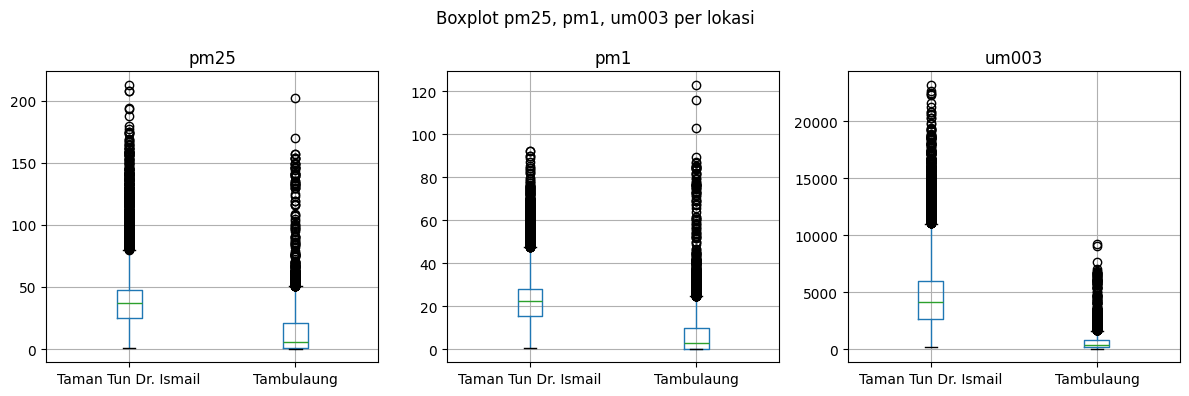


Jumlah baris yang berubah (pm25 = 0 menjadi NaN): 688

===== pm25 = 0 -> NaN: SEBELUM (5 data) =====


,location_name,datetime_from_utc,pm25
7216,Tambulaung,2026-01-01 13:00:00+00:00,0.0
7217,Tambulaung,2026-01-01 14:00:00+00:00,0.0
7218,Tambulaung,2026-01-01 15:00:00+00:00,0.0
7219,Tambulaung,2026-01-01 16:00:00+00:00,0.0
7220,Tambulaung,2026-01-01 17:00:00+00:00,0.0


===== pm25 = 0 -> NaN: SESUDAH (5 data) =====


,location_name,datetime_from_utc,pm25
7216,Tambulaung,2026-01-01 13:00:00+00:00,NaN
7217,Tambulaung,2026-01-01 14:00:00+00:00,NaN
7218,Tambulaung,2026-01-01 15:00:00+00:00,NaN
7219,Tambulaung,2026-01-01 16:00:00+00:00,NaN
7220,Tambulaung,2026-01-01 17:00:00+00:00,NaN


In [7]:
kolom_cek = ["pm25", "pm1", "um003"]
before = wide.copy()

# (a) Ringkasan IQR: hanya dihitung/dicatat, TIDAK dibuang
print("Ringkasan pencilan menurut aturan IQR (dipertahankan):")
for c in kolom_cek:
    q1, q3 = wide[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_atas, batas_bawah = q3 + 1.5 * iqr, q1 - 1.5 * iqr
    n_out = ((wide[c] > batas_atas) | (wide[c] < batas_bawah)).sum()
    print(f"  {c:6s}: batas [{batas_bawah:8.1f}, {batas_atas:8.1f}] -> {n_out:,} nilai di luar batas "
          f"({n_out / wide[c].notna().sum() * 100:.2f}%)")

# (b) Boxplot
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, c in zip(axes, kolom_cek):
    wide.boxplot(column=c, by="location_name", ax=ax)
    ax.set_title(c); ax.set_xlabel("")
plt.suptitle("Boxplot pm25, pm1, um003 per lokasi"); plt.tight_layout(); plt.show()

# (c) Error sensor: PM2.5 = 0 -> NaN
mask_nol = wide["pm25"] == 0
wide.loc[mask_nol, "pm25"] = np.nan

print(f"\nJumlah baris yang berubah (pm25 = 0 menjadi NaN): {mask_nol.sum():,}")
if mask_nol.sum() > 0:
    before_after(before.loc[mask_nol, ["location_name", "datetime_from_utc", "pm25"]],
                 wide.loc[mask_nol, ["location_name", "datetime_from_utc", "pm25"]],
                 "pm25 = 0 -> NaN")
else:
    print("Tidak ada nilai pm25 = 0, jadi tidak ada baris yang diubah.")

--------------------------------------------------------Ringkasan

In [8]:
print("Bentuk akhir data wide:", wide.shape)
print("\nNilai kosong (NaN) per kolom:")
display(wide.isna().sum().to_frame("jumlah_NaN").assign(persen=lambda d: (d.jumlah_NaN / len(wide) * 100).round(2)))
display(wide.head())

Bentuk akhir data wide: (14406, 7)

Nilai kosong (NaN) per kolom:


,jumlah_NaN,persen
location_name,0,0.00
datetime_from_utc,0,0.00
pm1,75,0.52
pm25,763,5.30
relativehumidity,75,0.52
temperature,75,0.52
um003,75,0.52


,location_name,datetime_from_utc,pm1,pm25,relativehumidity,temperature,um003
0,Taman Tun Dr. Ismail,2026-01-01 00:00:00+00:00,22.7,38.7,63.9,27.7,4310.0
1,Taman Tun Dr. Ismail,2026-01-01 01:00:00+00:00,21.5,36.1,63.3,27.7,3910.0
2,Taman Tun Dr. Ismail,2026-01-01 02:00:00+00:00,21.8,37.0,63.4,27.5,3980.0
3,Taman Tun Dr. Ismail,2026-01-01 03:00:00+00:00,21.7,36.8,59.8,28.6,4000.0
4,Taman Tun Dr. Ismail,2026-01-01 04:00:00+00:00,17.8,30.4,60.1,28.4,3250.0


--------------------------------------------------------Save CSV

In [9]:
OUTPUT_PATH = "GabunganDataset_BigData_eda.csv"

hasil = wide.copy()
hasil["datetime_from_utc"] = hasil["datetime_from_utc"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")  # format ISO 8601 (UTC)
hasil.to_csv(OUTPUT_PATH, index=False, encoding="utf-8")

cek = pd.read_csv(OUTPUT_PATH)
print(f"File disimpan: {OUTPUT_PATH}")
print(f"Jumlah baris dan kolom: {cek.shape}")
print("Kolom:", list(cek.columns))
print("Nilai kosong (NaN) per kolom:")
print(cek.isna().sum())
display(cek.head(5))

File disimpan: GabunganDataset_BigData_eda.csv
Jumlah baris dan kolom: (14406, 7)
Kolom: ['location_name', 'datetime_from_utc', 'pm1', 'pm25', 'relativehumidity', 'temperature', 'um003']
Nilai kosong (NaN) per kolom:
location_name          0
datetime_from_utc      0
pm1                   75
pm25                 763
relativehumidity      75
temperature           75
um003                 75
dtype: int64


,location_name,datetime_from_utc,pm1,pm25,relativehumidity,temperature,um003
0,Taman Tun Dr. Ismail,2026-01-01T00:00:00Z,22.7,38.7,63.9,27.7,4310.0
1,Taman Tun Dr. Ismail,2026-01-01T01:00:00Z,21.5,36.1,63.3,27.7,3910.0
2,Taman Tun Dr. Ismail,2026-01-01T02:00:00Z,21.8,37.0,63.4,27.5,3980.0
3,Taman Tun Dr. Ismail,2026-01-01T03:00:00Z,21.7,36.8,59.8,28.6,4000.0
4,Taman Tun Dr. Ismail,2026-01-01T04:00:00Z,17.8,30.4,60.1,28.4,3250.0


--------------------------------------------------------Persiapan Bagian Visualisasi

In [10]:
import os
os.makedirs("gambar", exist_ok=True)

# Waktu lokal (UTC+8 untuk kedua lokasi)
waktu_lokal = wide["datetime_from_utc"].dt.tz_convert("Asia/Kuala_Lumpur")
wide["bulan"] = waktu_lokal.dt.month
wide["jam_lokal"] = waktu_lokal.dt.hour

# Kategori AQI dari PM2.5 (EPA 2024). Baris dengan pm25 kosong tidak diberi kategori.
label_aqi = ["Baik", "Sedang", "Tidak sehat\n(sensitif)", "Tidak sehat", "Sangat tidak\nsehat", "Berbahaya"]
batas_aqi = [-0.001, 9.0, 35.4, 55.4, 125.4, 225.4, np.inf]
wide["kategori_aqi"] = pd.cut(wide["pm25"], bins=batas_aqi, labels=label_aqi, ordered=True)

print("Jumlah baris per kategori AQI (semua lokasi):")
print(wide["kategori_aqi"].value_counts(sort=False))
print("Baris tanpa kategori (pm25 kosong):", wide["kategori_aqi"].isna().sum())
display(wide[["location_name", "datetime_from_utc", "pm25", "kategori_aqi", "bulan", "jam_lokal"]].head(5))

Jumlah baris per kategori AQI (semua lokasi):
kategori_aqi
Baik                       3837
Sedang                     5239
Tidak sehat\n(sensitif)    3213
Tidak sehat                1143
Sangat tidak\nsehat         211
Berbahaya                     0
Name: count, dtype: int64
Baris tanpa kategori (pm25 kosong): 763


,location_name,datetime_from_utc,pm25,kategori_aqi,bulan,jam_lokal
0,Taman Tun Dr. Ismail,2026-01-01 00:00:00+00:00,38.7,Tidak sehat\n(sensitif),1,8
1,Taman Tun Dr. Ismail,2026-01-01 01:00:00+00:00,36.1,Tidak sehat\n(sensitif),1,9
2,Taman Tun Dr. Ismail,2026-01-01 02:00:00+00:00,37.0,Tidak sehat\n(sensitif),1,10
3,Taman Tun Dr. Ismail,2026-01-01 03:00:00+00:00,36.8,Tidak sehat\n(sensitif),1,11
4,Taman Tun Dr. Ismail,2026-01-01 04:00:00+00:00,30.4,Sedang,1,12


--------------------------------------------------------Visualisasi 1 - Tren rata-rata PM2.5 per bulan untuk kedua lokasi - Line Chart

Rata-rata PM2.5 per bulan (µg/m³):


location_name,Taman Tun Dr. Ismail,Tambulaung
bulan,,
1,30.0,4.0
2,28.1,3.9
3,35.2,14.1
4,36.5,16.3
5,24.8,3.3
6,29.0,4.0
7,37.2,6.6
8,48.6,29.0
9,69.5,39.5


Bulan terburuk Taman Tun Dr. Ismail: Okt* (78.3 µg/m³)
Bulan terburuk Tambulaung: Sep (39.5 µg/m³)


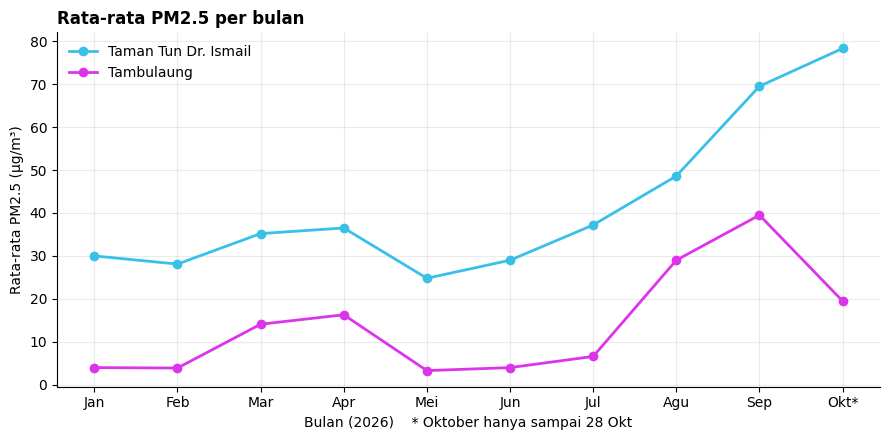

In [12]:
WARNA = {"Taman Tun Dr. Ismail": "#39c0e9", "Tambulaung": "#dc34eb"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt*"]

bulanan = wide.groupby(["location_name", "bulan"])["pm25"].mean().unstack(0).round(1)
print("Rata-rata PM2.5 per bulan (µg/m³):")
display(bulanan)
for lokasi in bulanan.columns:
    b = bulanan[lokasi].idxmax()
    print(f"Bulan terburuk {lokasi}: {nama_bulan[b-1]} ({bulanan[lokasi].max():.1f} µg/m³)")

fig, ax = plt.subplots(figsize=(9, 4.5))
for lokasi in bulanan.columns:
    ax.plot(bulanan.index, bulanan[lokasi], marker="o", markersize=6, linewidth=2,
            color=WARNA[lokasi], label=lokasi)
ax.set_xticks(range(1, 11)); ax.set_xticklabels(nama_bulan)
ax.set_xlabel("Bulan (2026)    * Oktober hanya sampai 28 Okt")
ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
ax.set_title("Rata-rata PM2.5 per bulan", loc="left", fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("gambar/1_tren_pm25_bulanan.png", dpi=150); plt.show()

--------------------------------------------------------Visualisasi 2 - Pola rata-rata PM2.5 per jam per dalam satu hari - Line Chart

Taman Tun Dr. Ismail: tertinggi pukul 00:00 (45.3), terendah pukul 17:00 (38.9) µg/m³
Tambulaung: tertinggi pukul 21:00 (16.8), terendah pukul 09:00 (13.6) µg/m³


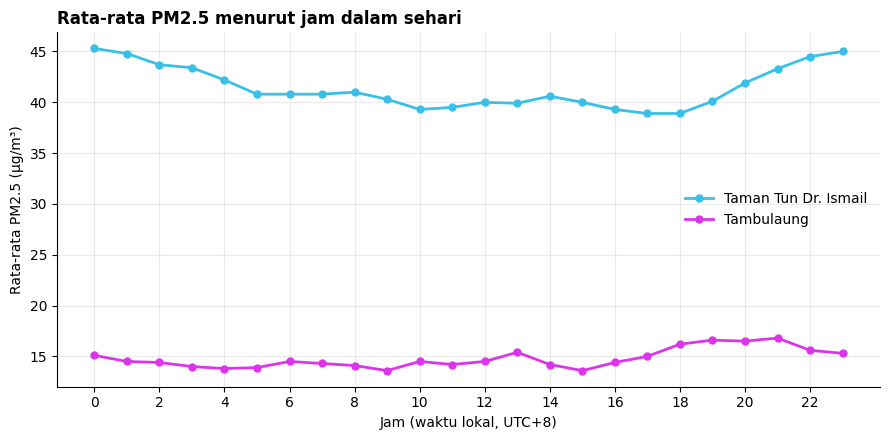

In [13]:
harian = wide.groupby(["location_name", "jam_lokal"])["pm25"].mean().unstack(0).round(1)
for lokasi in harian.columns:
    j = harian[lokasi].idxmax(); k = harian[lokasi].idxmin()
    print(f"{lokasi}: tertinggi pukul {j:02d}:00 ({harian[lokasi].max():.1f}), "
          f"terendah pukul {k:02d}:00 ({harian[lokasi].min():.1f}) µg/m³")

fig, ax = plt.subplots(figsize=(9, 4.5))
for lokasi in harian.columns:
    ax.plot(harian.index, harian[lokasi], marker="o", markersize=5, linewidth=2,
            color=WARNA[lokasi], label=lokasi)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Jam (waktu lokal, UTC+8)")
ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
ax.set_title("Rata-rata PM2.5 menurut jam dalam sehari", loc="left", fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("gambar/2_pola_pm25_per_jam.png", dpi=150); plt.show()

--------------------------------------------------------Visualisasi 3 - Distribusi Kategori AQI per lokasi - Bar Chart

Jumlah jam per kategori AQI:


location_name,Taman Tun Dr. Ismail,Tambulaung
kategori_aqi,,
Baik,271,3566
Sedang,3080,2159
Tidak sehat\n(sensitif),2654,559
Tidak sehat,1003,140
Sangat tidak\nsehat,172,39
Berbahaya,0,0


Persentase (%):


location_name,Taman Tun Dr. Ismail,Tambulaung
kategori_aqi,,
Baik,3.8,55.2
Sedang,42.9,33.4
Tidak sehat\n(sensitif),37.0,8.6
Tidak sehat,14.0,2.2
Sangat tidak\nsehat,2.4,0.6
Berbahaya,0.0,0.0


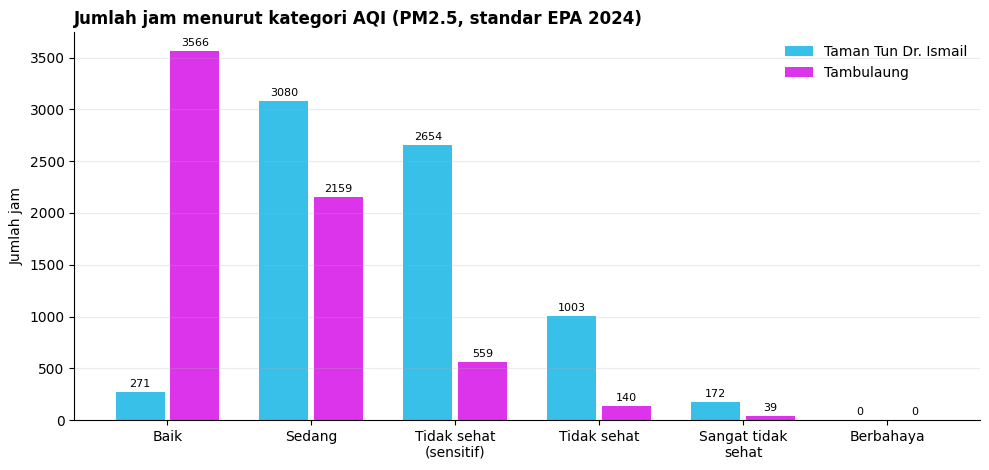

In [14]:
jumlah = (wide.dropna(subset=["kategori_aqi"])
              .groupby(["location_name", "kategori_aqi"], observed=False).size().unstack(0))
persen = (jumlah / jumlah.sum() * 100).round(1)
print("Jumlah jam per kategori AQI:"); display(jumlah)
print("Persentase (%):"); display(persen)

x = np.arange(len(jumlah)); lebar = 0.38
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, lokasi in enumerate(jumlah.columns):
    bar = ax.bar(x + (i - 0.5) * lebar, jumlah[lokasi], lebar - 0.04,
                 color=WARNA[lokasi], label=lokasi)
    ax.bar_label(bar, fmt="%d", fontsize=8, padding=2)
ax.set_xticks(x); ax.set_xticklabels(jumlah.index)
ax.set_ylabel("Jumlah jam")
ax.set_title("Jumlah jam menurut kategori AQI (PM2.5, standar EPA 2024)", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("gambar/3_distribusi_kategori_aqi.png", dpi=150); plt.show()

--------------------------------------------------------Visualisasi 4 - Korelasi antar Variabel - Heatmap

Korelasi dengan pm25:
pm1                 0.99
um003               0.93
temperature         0.12
relativehumidity   -0.07
Name: pm25, dtype: float64


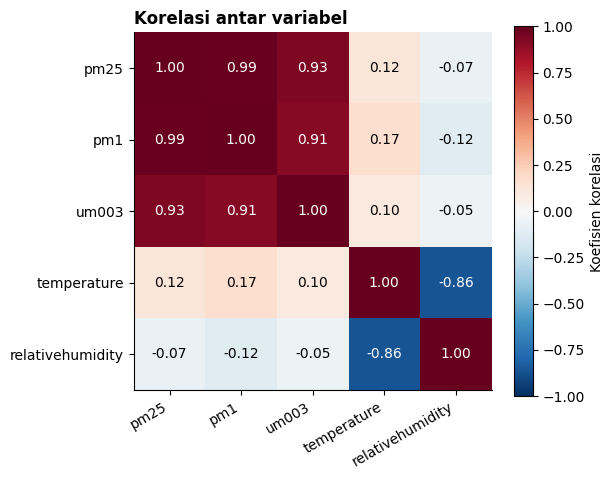

In [15]:
fitur = ["pm25", "pm1", "um003", "temperature", "relativehumidity"]
korelasi = wide[fitur].corr().round(2)
print("Korelasi dengan pm25:"); print(korelasi["pm25"].drop("pm25"))

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(korelasi, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(fitur))); ax.set_xticklabels(fitur, rotation=30, ha="right")
ax.set_yticks(range(len(fitur))); ax.set_yticklabels(fitur)
for i in range(len(fitur)):
    for j in range(len(fitur)):
        ax.text(j, i, f"{korelasi.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(korelasi.iloc[i, j]) > 0.6 else "black")
ax.grid(False); fig.colorbar(im, ax=ax, label="Koefisien korelasi")
ax.set_title("Korelasi antar variabel", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("gambar/4_korelasi.png", dpi=150); plt.show()